# Work Package 6 — Auditable national cell-year master


One row = one grid cell × one reference year. Start from the existing 40,166-row preparation table; preserve it and use its verified keys as the scaffold. Source tables supply accepted measurements; old bird summaries and ambiguous legacy losses are not carried into predictors. Species evidence remains separate.

A partial master is a useful evidence release, not an ML-ready dataset. A missing primary forest threshold or national fragmentation release is recorded explicitly. No imputation, model fitting or automatic feature deletion occurs.

## Cell 1 — Imports, paths and declared QA rules
Requires pandas, numpy, geopandas and matplotlib. All output writing is in Cells 10 and 12. No source data is changed.

In [13]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = next(p for base in [Path.cwd(), *Path.cwd().parents]
            for p in [base, base/"components/habitat_risk"] if (p/"configs/study.json").exists())
PREP = ROOT/"data/interim/hri/hri_cell_year_preparation.csv"
WP5 = ROOT/"data/processed/hri/wp5_v1"
OUT = ROOT/"data/processed/hri/wp6_v1"
KEYS = ["cell_id","reference_year"]
YEARS = list(range(2010,2024))
EXPECTED_ROWS = 40166
MIN_COVERAGE = .95
VERSION = "master-draft-v1"
cfg = json.loads((ROOT/"configs/study.json").read_text())
grid_id = f"lka_laea_{cfg['grid_size_m']}m"
input_paths = [PREP, ROOT/"configs/study.json"]
join_log, deferred, feature_specs, source_meta = [], [], {}, {}


## Cell 2 — Validate preparation keys, grid version and CRS
CRS belongs to geometry, not a CSV. Reproject the accepted geometry for metric area; source-grid provenance is verified separately. Fail on duplicate, missing, extra or non-integer keys rather than dropping records.

In [14]:
prep = pd.read_csv(PREP,low_memory=False)
grid_path = ROOT/f"data/interim/spatial/{grid_id}_grid.geojson"
grid = gpd.read_file(grid_path)
assert grid.crs is not None and grid.geometry.is_valid.all()
original_grid_crs = str(grid.crs)
grid = grid.to_crs(cfg["projected_crs"])
assert grid.cell_id.is_unique and grid.cell_id.notna().all()
assert prep[KEYS].notna().all().all()
year_values = pd.to_numeric(prep.reference_year,errors="raise")
assert year_values.eq(year_values.astype(int)).all()
prep["reference_year"] = year_values.astype(int)
assert len(prep)==EXPECTED_ROWS and not prep.duplicated(KEYS).any()
expected = pd.MultiIndex.from_product([grid.cell_id,YEARS],names=KEYS)
actual = pd.MultiIndex.from_frame(prep[KEYS])
assert len(expected)==EXPECTED_ROWS
assert expected.difference(actual).empty and actual.difference(expected).empty
master = prep[KEYS].sort_values(KEYS).reset_index(drop=True)
input_paths.append(grid_path)
classification = pd.DataFrame({"column":prep.columns})
bird_columns = {"recorded_endemic_species","endemic_observation_records","endemic_occurrence_evidence"}
classification["treatment"] = classification.column.map(
    lambda c:"key retained" if c in KEYS else
    "bird evidence excluded; use separate WP2 species table" if c in bird_columns else
    "legacy column not carried; use independently documented source table")
display(classification)
print("Verified scaffold",master.shape,"metric CRS",grid.crs)


,column,treatment
0,cell_id,key retained
1,grid_x,legacy column not carried; use independently d...
2,grid_y,legacy column not carried; use independently d...
3,land_area_km2,legacy column not carried; use independently d...
4,reference_year,key retained
5,annual_mean_temperature_c,legacy column not carried; use independently d...
6,annual_mean_temperature_c_coverage,legacy column not carried; use independently d...
7,annual_precipitation_mm,legacy column not carried; use independently d...
8,annual_precipitation_mm_coverage,legacy column not carried; use independently d...
9,weather_status,legacy column not carried; use independently d...


Verified scaffold (40166, 2) metric CRS +proj=laea +lat_0=7.9 +lon_0=80.7 +datum=WGS84 +units=m +no_defs +type=crs


## Cell 3 — Verify WP5 provenance and freeze source selection
Verify every upstream input checksum in the WP5 manifest. This detects changed inputs, but does not reproduce the WP5 methods or prove ecological validity. Hashing large rasters is foreground work and prints progress.

Only approved primary forest and national fragmentation scenarios can enter the master. Optional sources require their own per-feature specifications before joining; filenames alone are insufficient.

In [15]:
def sha256(path):
    h=hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda:f.read(8*1024*1024),b""): h.update(block)
    return h.hexdigest()
manifest_path = WP5/"metadata_and_audit.json"
assert manifest_path.exists(),"Run and review WP5 first."
manifest = json.loads(manifest_path.read_text())
assert manifest["grid_version"]==grid_id and manifest["years"]==YEARS
assert manifest["prediction_cutoff"]=="end of year t"
assert manifest.get("input_sha256"),"Missing WP5 source provenance"
for relative, digest in manifest["input_sha256"].items():
    path=ROOT/relative
    print("Checking WP5 source:",path.name,flush=True)
    assert path.exists() and sha256(path)==digest, f"Source changed: {relative}; rebuild WP5"
input_paths.append(manifest_path)
threshold=manifest.get("primary_threshold")
selected=[("climate",WP5/"climate_cell_year.csv",KEYS),
          ("terrain",WP5/"terrain_cell.csv",["cell_id"])]
if threshold is not None and str(manifest.get("threshold_rationale","")).strip():
    selected.append(("forest",WP5/"forest_threshold_scenarios.csv",KEYS))
else:
    deferred.append("Forest predictors: primary canopy threshold and rationale not approved.")
frag_path=WP5/"fragmentation_threshold_scenarios.csv"
frag_meta=manifest["tables"].get("fragmentation_threshold_scenarios",{})
if threshold is not None and frag_path.exists() and frag_meta.get("complete_national") is True:
    selected.append(("fragmentation",frag_path,KEYS))
else:
    deferred.append("Fragmentation: national release and approved threshold required; PREVIEW excluded.")
deferred += [
    "Vegetation: no reviewed per-feature source specification admitted here.",
    "Human pressure: no reviewed temporally compatible source specification admitted here.",
    "Conservation designation: static/historical scope must be approved before admission."]
print("Admitted source groups:",[s[0] for s in selected])
display(pd.Series(deferred))


Checking WP5 source: study.json
Checking WP5 source: lka_laea_5000m_canopy_loss_histogram.csv
Checking WP5 source: lka_laea_5000m_forest_evidence.csv
Checking WP5 source: lka_laea_5000m_grid.geojson
Checking WP5 source: lka_laea_5000m_terrain_features.csv
Checking WP5 source: lka_laea_5000m_weather_features.csv
Checking WP5 source: Hansen_GFC-2024-v1.12_datamask_10N_070E.tif
Checking WP5 source: Hansen_GFC-2024-v1.12_datamask_10N_080E.tif
Checking WP5 source: Hansen_GFC-2024-v1.12_lossyear_10N_070E.tif
Checking WP5 source: Hansen_GFC-2024-v1.12_lossyear_10N_080E.tif
Checking WP5 source: Hansen_GFC-2024-v1.12_treecover2000_10N_070E.tif
Checking WP5 source: Hansen_GFC-2024-v1.12_treecover2000_10N_080E.tif
Admitted source groups: ['climate', 'terrain']


0    Forest predictors: primary canopy threshold an...
1    Fragmentation: national release and approved t...
2    Vegetation: no reviewed per-feature source spe...
3    Human pressure: no reviewed temporally compati...
4    Conservation designation: static/historical sc...
dtype: object

## Cell 4 — Explicit feature definitions
Each accepted measurement has a unit, formula, temporal window, risk interpretation and bounds. Bounds are QA checks, not ecological risk classes. Temperature extremes are not arbitrarily clipped. Metadata-only source fields remain quality/context, not predictors.

Extend this registry explicitly when adding a new source. An unknown numeric column cannot silently become a predictor.

In [16]:
def spec(unit,formula,window,role="predictor",lower=None,upper=None,risk="context; no universal risk direction",coverage=None):
    return dict(unit=unit,formula=formula,temporal_window=window,role=role,
                lower=lower,upper=upper,risk_interpretation=risk,coverage_column=coverage)
DEFS={
 "annual_mean_temperature_c":spec("degC","day-weighted annual mean of t2m minus 273.15","Jan–Dec t",coverage="annual_mean_temperature_c_coverage"),
 "annual_precipitation_mm":spec("mm/year","sum monthly mean-daily precipitation × days × 1000","Jan–Dec t",lower=0,coverage="annual_precipitation_mm_coverage"),
 "temperature_c_anomaly":spec("degC","annual temperature minus complete 2010–2014 mean; t>=2015","baseline 2010–2014; current t",coverage="annual_mean_temperature_c_coverage"),
 "precipitation_mm_anomaly":spec("mm","annual precipitation minus complete 2010–2014 mean; t>=2015","baseline 2010–2014; current t",coverage="annual_precipitation_mm_coverage"),
 "temperature_c_trailing5_slope_per_year":spec("degC/year","OLS slope across five complete annual values","t−4 through t",coverage="annual_mean_temperature_c_coverage"),
 "precipitation_mm_trailing5_slope_per_year":spec("mm/year per year","OLS slope across five complete annual totals","t−4 through t",coverage="annual_precipitation_mm_coverage"),
 "mean_elevation_m":spec("m","valid-pixel mean of source terrain","static snapshot",coverage="terrain_valid_fraction"),
 "elevation_sd_m":spec("m","valid-pixel elevation standard deviation","static snapshot",lower=0,coverage="terrain_valid_fraction"),
 "mean_slope_degrees":spec("degree","mean derived terrain slope","static snapshot",lower=0,upper=90,coverage="slope_valid_fraction"),
 "baseline_canopy_percent":spec("percent","area-weighted year-2000 canopy on mapped valid land","year 2000",lower=0,upper=100,coverage="forest_coverage"),
 "baseline_forest_ha":spec("ha","year-2000 area at/above selected canopy threshold","year 2000",lower=0,coverage="forest_coverage"),
 "remaining_baseline_forest_proportion":spec("fraction","(baseline forest − losses 2001..t)/mapped valid land","2000 baseline; losses through t",lower=0,upper=1,coverage="forest_coverage"),
 "years_since_previous_loss":spec("year","t − latest mapped loss year strictly before t","2001 through t−1",lower=0,coverage="forest_coverage"),
 "cell_patch_count":spec("count","4-neighbour contextual labels intersecting cell","end of t",lower=0,coverage="mapped_land_coverage"),
 "mean_cell_patch_ha":spec("ha","mean area of cell-clipped forest patches","end of t",lower=0,coverage="mapped_land_coverage"),
 "largest_cell_patch_land_fraction":spec("fraction","largest cell-clipped patch / valid mapped cell land","end of t",lower=0,upper=1,coverage="mapped_land_coverage"),
 "edge_m_per_land_ha":spec("m/ha","forest/nonforest internal valid interfaces / valid land ha","end of t",lower=0,coverage="mapped_land_coverage"),
 "mean_nearest_patch_centroid_m":spec("m","mean nearest contextual patch centroid distance; 1 km halo","end of t",lower=0,coverage="mapped_land_coverage"),
}
for stem,window in [("annual_loss","t"),("cumulative_prior_loss","2001 through t−1"),
                    ("previous_1yr_loss","t−1"),("previous_3yr_loss","t−3 through t−1"),
                    ("previous_5yr_loss","t−5 through t−1")]:
    DEFS[stem+"_ha"]=spec("ha","sum mapped eligible loss area / 10000",window,lower=0,
                        risk="higher loss indicates greater pressure, conditional on habitat relevance",coverage="forest_coverage")
    DEFS[stem+"_fraction_of_baseline"]=spec("fraction","loss ha / selected baseline forest ha; undefined if baseline=0",
                        window,lower=0,upper=1,risk="greater loss pressure",coverage="forest_coverage")
QUALITY = {
 "annual_mean_temperature_c_coverage":"fraction of cell covered by finite full-year temperature",
 "annual_precipitation_mm_coverage":"fraction of cell covered by finite full-year precipitation",
 "terrain_valid_fraction":"valid terrain pixels / sampled terrain pixels",
 "slope_valid_fraction":"valid slope fraction",
 "forest_coverage":"observed forest-source sampled footprint fraction",
 "mapped_land_coverage":"valid mapped land pixels / cell-included pixels",
 "sampled_to_polygon_area_ratio":"sampled footprint area / grid polygon area",
 "terrain_sampled_pixels":"number of sampled terrain pixels",
 "terrain_valid_pixels":"number of valid terrain pixels",
 "weather_status":"source weather eligibility status",
 "terrain_status":"source terrain eligibility status",
 "feature_status":"source forest eligibility status",
 "previous_loss_detected":"whether a loss before t was detected within source record",
 **{f"previous_{n}yr_window_complete":f"all {n} prior years available" for n in [1,3,5]}
}


## Cell 5 — Join sources without multiplying rows
Annual tables must cover the national scaffold, including explicitly missing measurements. Static tables must cover the national cells. Join source quality columns with a group prefix to prevent collisions. Record omitted columns instead of retaining unexplained suffixes.

In [17]:
omitted=[]
for group,path,keys in selected:
    assert path.exists(),path
    frame=pd.read_csv(path,low_memory=False)
    if group in ["forest","fragmentation"]:
        frame=frame.loc[frame.canopy_threshold_percent.eq(threshold)].drop(columns="canopy_threshold_percent")
    assert frame[keys].notna().all().all() and not frame.duplicated(keys).any(),group
    assert set(frame.cell_id)==set(grid.cell_id),group
    if "reference_year" in keys:
        assert pd.MultiIndex.from_frame(frame[keys]).difference(expected).empty
        assert expected.difference(pd.MultiIndex.from_frame(frame[keys])).empty
    source_meta[group]=manifest["tables"].get(
        "forest_threshold_scenarios" if group=="forest" else
        "fragmentation_threshold_scenarios" if group=="fragmentation" else
        "climate_cell_year" if group=="climate" else "terrain_cell",{})
    keep=keys+[c for c in frame if c in DEFS or c in QUALITY]
    omitted += [{"source":group,"column":c} for c in frame if c not in keep]
    frame=frame[keep]
    rename={c:f"{group}__{c}" for c in frame if c not in keys}
    for c,new in rename.items():
        entry=DEFS.get(c, spec(
            "fraction" if ("coverage" in c or "fraction" in c or "ratio" in c) else
            "pixels" if "pixels" in c else "flag/status",
            QUALITY[c] if c in QUALITY else "", "source support",role="quality"))
        entry=entry.copy()
        entry.update(source_table=str(path.relative_to(ROOT)),source_group=group,
                     source_feature=c,source_sha256=sha256(path),
                     source_metadata=json.dumps(source_meta[group],ensure_ascii=False),
                     grid_version=grid_id,spatial_crs=str(grid.crs),
                     availability_rule="measurement window ends by t; retrospective source release, not verified real-time availability",
                     missing_value_meaning="source missing/insufficient coverage/undefined window; inspect QA reason")
        if entry["coverage_column"]: entry["coverage_column"]=group+"__"+entry["coverage_column"]
        feature_specs[new]=entry
    overlap=(set(frame.rename(columns=rename))-set(keys)) & set(master)
    assert not overlap,overlap
    before=len(master)
    master=master.merge(frame.rename(columns=rename),on=keys,how="left",
                        validate="one_to_one" if len(keys)==2 else "many_to_one")
    assert len(master)==before==EXPECTED_ROWS
    join_log.append({"source":group,"before":before,"after":len(master),"source_rows":len(frame)})
    input_paths.append(path)
raw=master.copy(deep=True)
print("Joined master:",raw.shape)
display(pd.DataFrame(join_log))


Joined master: (40166, 19)


,source,before,after,source_rows
0,climate,40166,40166,40166
1,terrain,40166,40166,2869


## Cell 6 — Mask impossible/low-coverage values; retain all rows
Each predictor gets a reason column. Original measurements remain in master_cell_year_raw. Outliers inside valid physical ranges are investigated in plots, not automatically deleted. No imputation is performed.

In [18]:
clean=raw.copy(deep=True)
value_audits=[]
# Polygon-area arithmetic can produce 1 + tiny floating-point error.
COVERAGE_TOLERANCE = 1e-9
coverage_rounding_counts = {}
predictors=[c for c,s in feature_specs.items() if s["role"]=="predictor"]
for c in predictors:
    s=feature_specs[c]
    original=clean[c]
    v=pd.to_numeric(original,errors="coerce")
    reasons=pd.Series("valid",index=clean.index)
    reasons.loc[original.isna()]="source_missing_or_undefined"
    bad=(original.notna() & v.isna()) | (v.notna() & ~np.isfinite(v))
    if s["lower"] is not None: bad |= v.lt(s["lower"])
    if s["upper"] is not None: bad |= v.gt(s["upper"])
    if s["source_feature"]=="cell_patch_count": bad |= v.notna() & v.mod(1).ne(0)
    coverage=s["coverage_column"]
    if coverage:
        assert coverage in clean,(c,coverage)
        q=pd.to_numeric(clean[coverage],errors="coerce")
        non_numeric = clean[coverage].notna() & q.isna()
        outside = q.notna() & (~np.isfinite(q) | q.lt(-COVERAGE_TOLERANCE) | q.gt(1 + COVERAGE_TOLERANCE))
        assert not (non_numeric | outside).any(), (coverage, 'Invalid coverage beyond rounding tolerance', q.loc[non_numeric | outside].head().tolist())
        # Clip only after validating tolerance; raw remains unchanged.
        coverage_rounding_counts.setdefault(coverage, int((q.lt(0) | q.gt(1)).sum()))
        q = q.clip(0, 1)
        clean[coverage] = q
        reasons.loc[q.isna() | q.lt(MIN_COVERAGE)]="insufficient_or_missing_coverage"
    reasons.loc[bad]="impossible_or_non_numeric"
    clean[c]=v.where(reasons.eq("valid"))
    flag=c+"__qa_reason"
    clean[flag]=reasons
    feature_specs[flag]={**s,"role":"quality","unit":"category",
        "formula":"source missingness, physical limits and coverage checks on "+c,"coverage_column":None}
    value_audits.append({"feature":c,"impossible_rows":int(bad.sum()),
                        "accepted_rows":int(clean[c].notna().sum())})
# Cross-variable bound: each loss area must not exceed its eligible baseline forest.
baseline="forest__baseline_forest_ha"
if baseline in clean:
    for c in [c for c in predictors if c.startswith("forest__") and "loss" in c and c.endswith("_ha")]:
        bad=clean[c].gt(clean[baseline]+1e-6)
        clean.loc[bad,c]=np.nan
        clean.loc[bad,c+"__qa_reason"]="loss_exceeds_baseline"
assert len(clean)==EXPECTED_ROWS and not clean.duplicated(KEYS).any()
display(pd.DataFrame(value_audits))


,feature,impossible_rows,accepted_rows
0,climate__annual_mean_temperature_c,0,35154
1,climate__annual_precipitation_mm,0,35154
2,climate__temperature_c_anomaly,0,22599
3,climate__temperature_c_trailing5_slope_per_year,0,25110
4,climate__precipitation_mm_anomaly,0,22599
5,climate__precipitation_mm_trailing5_slope_per_...,0,25110
6,terrain__mean_elevation_m,0,37870
7,terrain__elevation_sd_m,0,37870
8,terrain__mean_slope_degrees,0,36372


## Cell 7 — Temporal alignment: independently recompute climate windows
Validate anomalies and slopes from annual values rather than accepting column names as evidence. The forest source remains subject to WP5's future-event perturbation test; this notebook does not claim to revalidate raw forest processing. Full-period correlations/plots are descriptive only.

In [19]:
temporal_checks=[]
for prefix,annual in [("temperature_c","annual_mean_temperature_c"),("precipitation_mm","annual_precipitation_mm")]:
    value="climate__"+annual
    if value not in raw: continue
    ordered=raw.sort_values(KEYS)
    base=ordered.loc[ordered.reference_year.between(2010,2014)].groupby("cell_id")[value].agg(["mean","count"])
    reference=ordered.cell_id.map(base["mean"].where(base["count"].eq(5)))
    calculated=(ordered[value]-reference).where(ordered.reference_year.ge(2015))
    anomaly="climate__"+prefix+"_anomaly"
    if anomaly in raw:
        assert np.allclose(calculated,ordered[anomaly],equal_nan=True)
        temporal_checks.append(anomaly+": independently recomputed; baseline available before t")
    slope="climate__"+prefix+"_trailing5_slope_per_year"
    if slope in raw:
        calculated=ordered.groupby("cell_id")[value].transform(
            lambda s:s.rolling(5,min_periods=5).apply(lambda a:np.polyfit(np.arange(5),a,1)[0],raw=True))
        assert np.allclose(calculated,ordered[slope],equal_nan=True)
        temporal_checks.append(slope+": complete trailing five-year window recomputed")
assert not any(c in clean for c in bird_columns)
temporal_checks.append("Bird columns excluded; no future-outcome table joined.")
display(pd.Series(temporal_checks))


0    climate__temperature_c_anomaly: independently ...
1    climate__temperature_c_trailing5_slope_per_yea...
2    climate__precipitation_mm_anomaly: independent...
3    climate__precipitation_mm_trailing5_slope_per_...
4    Bird columns excluded; no future-outcome table...
dtype: object

## Cell 8 — Missingness overall, by year and by reason
The report includes all columns; separate QA reasons explain why predictor values are absent. An undefined time-since-loss or zero-baseline fraction is not an observed zero.

In [20]:
missing_rows=[]
for label,part in [("all",clean)]+[(str(y),clean.loc[clean.reference_year.eq(y)]) for y in YEARS]:
    for c in clean:
        missing_rows.append({"feature":c,"year_group":label,"total_rows":len(part),
            "valid_rows":int(part[c].notna().sum()),"missing_rows":int(part[c].isna().sum()),
            "missing_percent":100*part[c].isna().mean()})
missing_report=pd.DataFrame(missing_rows)
reason_report=pd.concat([clean[c+"__qa_reason"].value_counts(dropna=False).rename_axis("reason")
    .reset_index(name="rows").assign(feature=c) for c in predictors],ignore_index=True)
display(missing_report.query("year_group == 'all'").sort_values("missing_percent",ascending=False))
display(reason_report)


,feature,year_group,total_rows,valid_rows,missing_rows,missing_percent
9,climate__precipitation_mm_anomaly,all,40166,22599,17567,43.735996
7,climate__temperature_c_anomaly,all,40166,22599,17567,43.735996
10,climate__precipitation_mm_trailing5_slope_per_...,all,40166,25110,15056,37.484440
8,climate__temperature_c_trailing5_slope_per_year,all,40166,25110,15056,37.484440
2,climate__annual_mean_temperature_c,all,40166,35154,5012,12.478215
4,climate__annual_precipitation_mm,all,40166,35154,5012,12.478215
17,terrain__mean_slope_degrees,all,40166,36372,3794,9.445800
16,terrain__elevation_sd_m,all,40166,37870,2296,5.716277
15,terrain__mean_elevation_m,all,40166,37870,2296,5.716277
13,terrain__terrain_valid_fraction,all,40166,40082,84,0.209132


,reason,rows,feature
0,valid,35154,climate__annual_mean_temperature_c
1,insufficient_or_missing_coverage,5012,climate__annual_mean_temperature_c
2,valid,35154,climate__annual_precipitation_mm
3,insufficient_or_missing_coverage,5012,climate__annual_precipitation_mm
4,valid,22599,climate__temperature_c_anomaly
5,source_missing_or_undefined,12555,climate__temperature_c_anomaly
6,insufficient_or_missing_coverage,5012,climate__temperature_c_anomaly
7,valid,25110,climate__temperature_c_trailing5_slope_per_year
8,source_missing_or_undefined,10044,climate__temperature_c_trailing5_slope_per_year
9,insufficient_or_missing_coverage,5012,climate__temperature_c_trailing5_slope_per_year


## Cell 9 — Correlation and VIF diagnostics
Use predictor measurements only. Spearman correlations use pairwise complete observations; save pairwise sample counts. VIF uses a common complete-case cohort, standardisation and an intercept. At most 5,000 rows are sampled reproducibly for tractable descriptive diagnostics. Constant variables and insufficient sample sizes are reported. High VIF is not automatic permission to delete a feature; predictive selection belongs inside training folds.

In [21]:
numeric=clean[predictors].apply(pd.to_numeric,errors="coerce")
correlation=numeric.corr(method="spearman",min_periods=30)
available=numeric.notna().astype("int64")
correlation_n=available.T @ available
usable=[c for c in predictors if numeric[c].nunique(dropna=True)>1]
complete=numeric[usable].dropna()
if len(complete)>5000: complete=complete.sample(5000,random_state=42)
vif_rows=[]
if len(usable)>=2 and len(complete)>len(usable)+1:
    std=complete.std(ddof=0)
    varying=std[std.gt(0)].index.tolist()
    z=(complete[varying]-complete[varying].mean())/std[varying]
    for c in usable:
        if c not in varying:
            vif_rows.append({"feature":c,"vif":np.nan,"rows":len(z),"status":"constant_on_complete_cases"});continue
        y=z[c].to_numpy()
        others=z.drop(columns=c).to_numpy()
        design=np.column_stack([np.ones(len(z)),others])
        fitted=design @ np.linalg.lstsq(design,y,rcond=None)[0]
        residual=((y-fitted)**2).sum(); total=((y-y.mean())**2).sum()
        vif=np.inf if residual <= 1e-12*total else total/residual
        vif_rows.append({"feature":c,"vif":vif,"rows":len(z),"status":"descriptive_complete_case"})
else:
    vif_rows=[{"feature":c,"vif":np.nan,"rows":len(complete),"status":"insufficient_complete_cases"}
              for c in usable]
vif_report=pd.DataFrame(vif_rows,columns=["feature","vif","rows","status"])
display(vif_report)


,feature,vif,rows,status
0,climate__annual_mean_temperature_c,10.474474,5000,descriptive_complete_case
1,climate__annual_precipitation_mm,2.744492,5000,descriptive_complete_case
2,climate__temperature_c_anomaly,2.448347,5000,descriptive_complete_case
3,climate__temperature_c_trailing5_slope_per_year,1.740155,5000,descriptive_complete_case
4,climate__precipitation_mm_anomaly,2.726595,5000,descriptive_complete_case
5,climate__precipitation_mm_trailing5_slope_per_...,1.707653,5000,descriptive_complete_case
6,terrain__mean_elevation_m,7.658662,5000,descriptive_complete_case
7,terrain__elevation_sd_m,9.573519,5000,descriptive_complete_case
8,terrain__mean_slope_degrees,11.850140,5000,descriptive_complete_case


## Cell 10 — Display and save distribution plots
This is the first output-writing cell. Histograms and annual medians help detect suspicious units, constants and source changes. These are national descriptive summaries, not model-validation results.

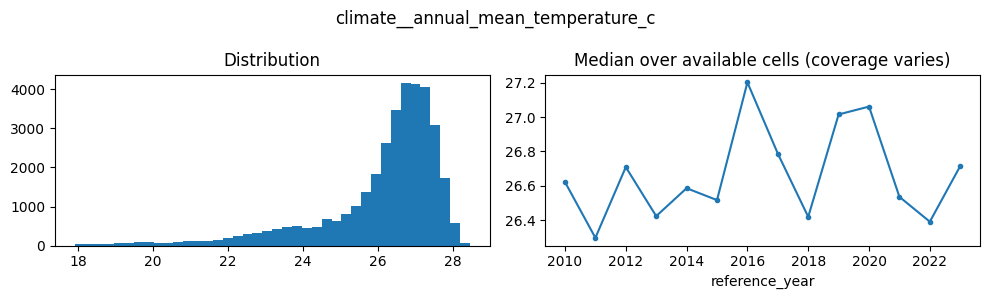

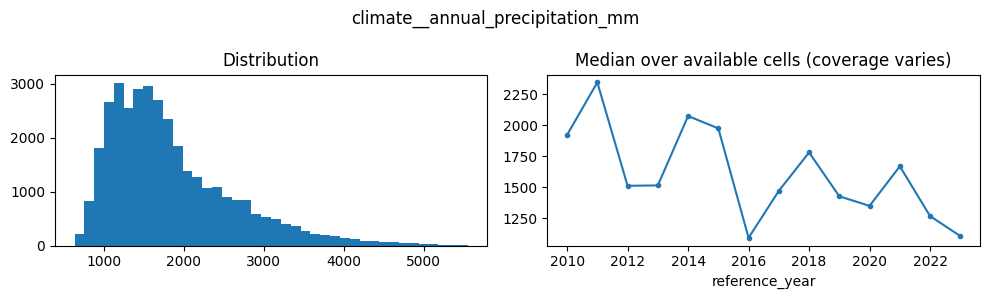

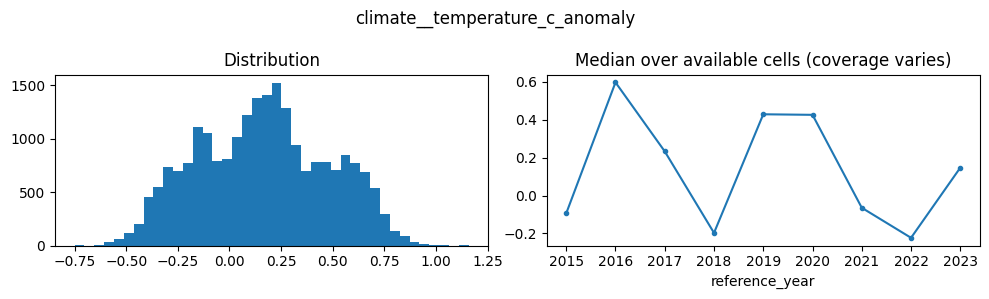

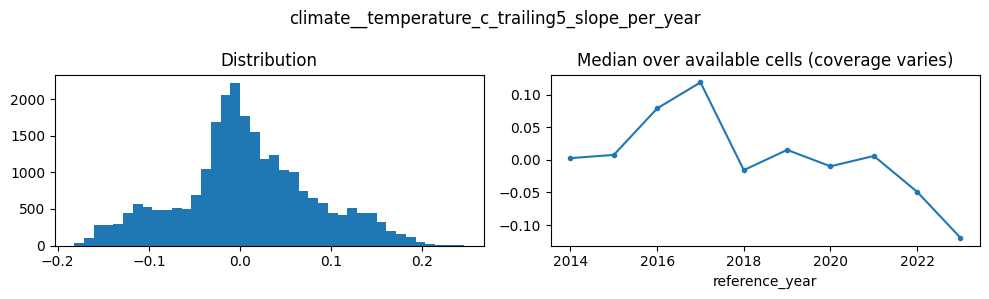

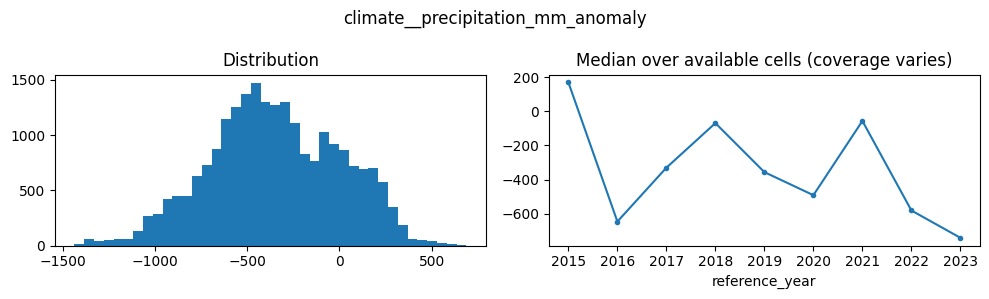

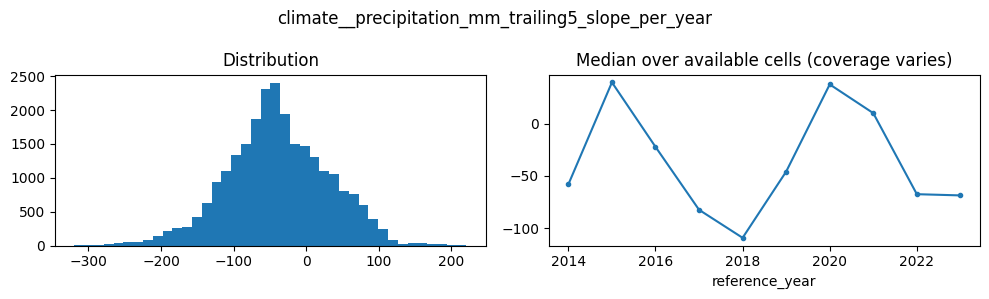

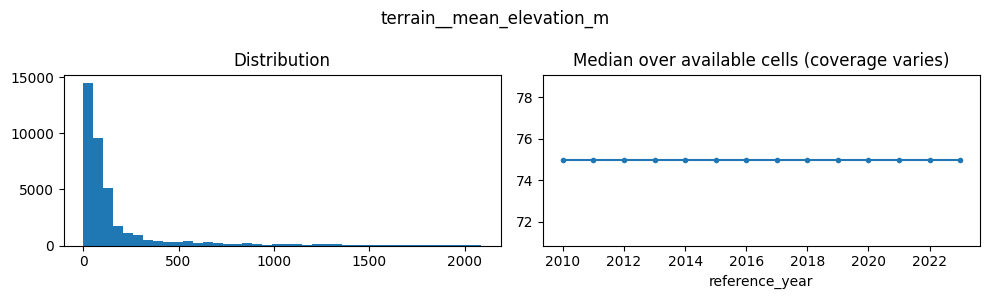

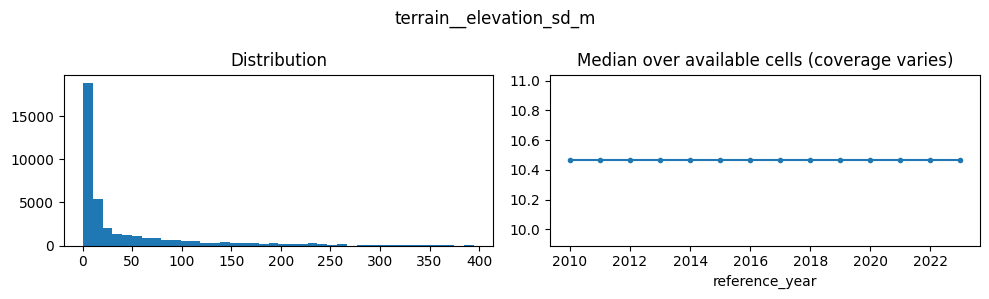

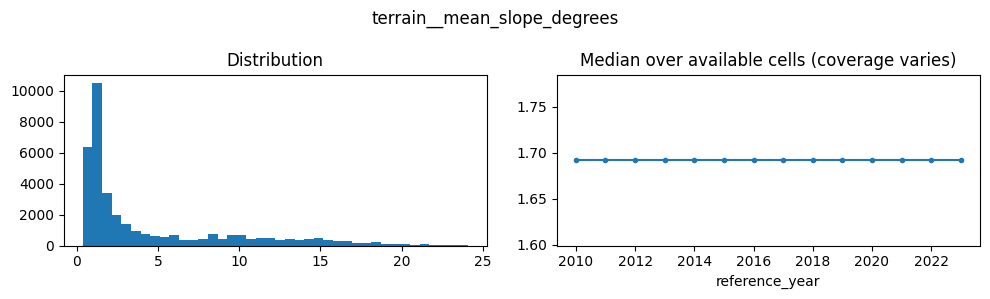

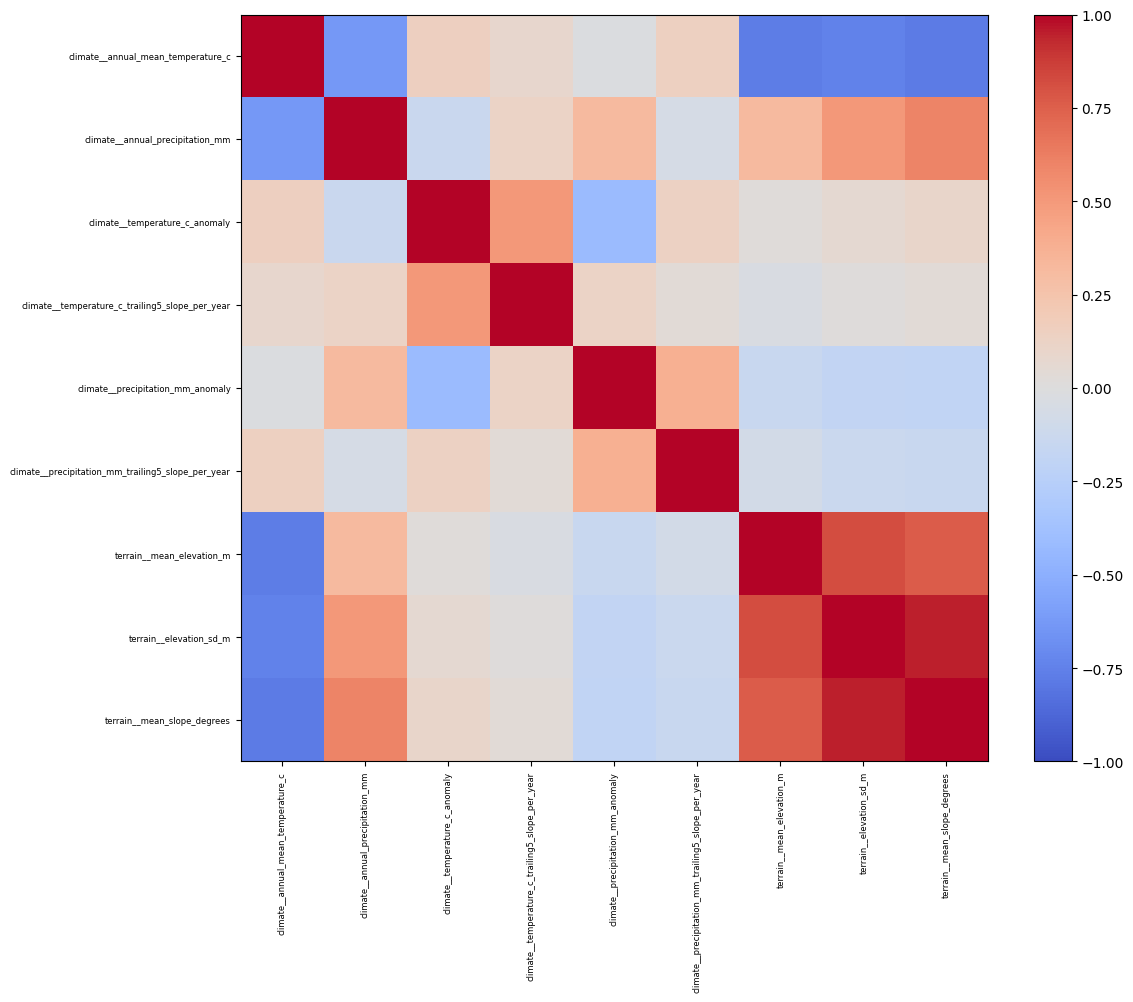

In [22]:
FIG=OUT/"figures"
FIG.mkdir(parents=True,exist_ok=True)
plot_paths=[]
for c in predictors:
    fig,axes=plt.subplots(1,2,figsize=(10,3))
    values=clean[c].dropna()
    if len(values): axes[0].hist(values,bins=40)
    else: axes[0].text(.1,.5,"No accepted values",transform=axes[0].transAxes)
    axes[0].set_title("Distribution")
    clean.groupby("reference_year")[c].median().plot(ax=axes[1],marker=".")
    axes[1].set_title("Median over available cells (coverage varies)")
    fig.suptitle(c); fig.tight_layout()
    path=FIG/(c+".png");fig.savefig(path,dpi=140);plot_paths.append(str(path.relative_to(OUT)))
    plt.show();plt.close(fig)
if correlation.shape[0]:
    fig,ax=plt.subplots(figsize=(12,10))
    im=ax.imshow(correlation.to_numpy(),vmin=-1,vmax=1,cmap="coolwarm")
    ax.set_xticks(range(len(correlation)),correlation.columns,rotation=90,fontsize=6)
    ax.set_yticks(range(len(correlation)),correlation.index,fontsize=6)
    fig.colorbar(im,ax=ax);fig.tight_layout()
    path=FIG/"spearman.png";fig.savefig(path,dpi=140);plot_paths.append(str(path.relative_to(OUT)))
    plt.show();plt.close(fig)


## Cell 11 — Feature dictionary and honest completion status
Every exported column gets a definition. Per-source metadata carries source version, spatial support and limitations. Raw measurements plus generated QA columns remain distinguishable. The dictionary also records the raw input checksum. Review this dictionary with your supervisor before accepting any predictor.

In [23]:
dictionary_rows=[]
for c in clean:
    if c in KEYS:
        s={"role":"identifier","unit":"cell identifier" if c=="cell_id" else "calendar year",
           "formula":"verified national grid identifier" if c=="cell_id" else "end-of-year assessment reference",
           "temporal_window":"2010–2023","source_table":str(PREP.relative_to(ROOT)),
           "source_sha256":sha256(PREP),"grid_version":grid_id,"spatial_crs":str(grid.crs)}
    else: s=feature_specs[c]
    dictionary_rows.append({"feature":c,**s,"in_raw_master":c in raw,"method_version":VERSION})
dictionary=pd.DataFrame(dictionary_rows)
assert dictionary.feature.is_unique and set(dictionary.feature)==set(clean.columns)
release_status="partial_environmental_master" if deferred else "candidate_environmental_master_requires_review"
print("Release status:",release_status)
display(dictionary)
print("Species evidence remains separate: data/processed/hri/wp2_v1/hri_cell_year_species_evidence.csv")


Release status: partial_environmental_master


,feature,role,unit,formula,temporal_window,source_table,source_sha256,grid_version,spatial_crs,in_raw_master,method_version,lower,upper,risk_interpretation,coverage_column,source_group,source_feature,source_metadata,availability_rule,missing_value_meaning
0,cell_id,identifier,cell identifier,verified national grid identifier,2010–2023,data/interim/hri/hri_cell_year_preparation.csv,868f04f1ffd878272c55f2ba25ecd33c5fe8f0739ea9b8...,lka_laea_5000m,+proj=laea +lat_0=7.9 +lon_0=80.7 +datum=WGS84...,True,master-draft-v1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,reference_year,identifier,calendar year,end-of-year assessment reference,2010–2023,data/interim/hri/hri_cell_year_preparation.csv,868f04f1ffd878272c55f2ba25ecd33c5fe8f0739ea9b8...,lka_laea_5000m,+proj=laea +lat_0=7.9 +lon_0=80.7 +datum=WGS84...,True,master-draft-v1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,climate__annual_mean_temperature_c,predictor,degC,day-weighted annual mean of t2m minus 273.15,Jan–Dec t,data/processed/hri/wp5_v1/climate_cell_year.csv,30bf52ab8e0018d9d6f5db1306089b04eeed12a843640e...,lka_laea_5000m,+proj=laea +lat_0=7.9 +lon_0=80.7 +datum=WGS84...,True,master-draft-v1,NaN,NaN,context; no universal risk direction,climate__annual_mean_temperature_c_coverage,climate,annual_mean_temperature_c,"{""source"": ""ERA5-Land existing audited annual ...",measurement window ends by t; retrospective so...,source missing/insufficient coverage/undefined...
3,climate__annual_mean_temperature_c_coverage,quality,fraction,fraction of cell covered by finite full-year t...,source support,data/processed/hri/wp5_v1/climate_cell_year.csv,30bf52ab8e0018d9d6f5db1306089b04eeed12a843640e...,lka_laea_5000m,+proj=laea +lat_0=7.9 +lon_0=80.7 +datum=WGS84...,True,master-draft-v1,NaN,NaN,context; no universal risk direction,None,climate,annual_mean_temperature_c_coverage,"{""source"": ""ERA5-Land existing audited annual ...",measurement window ends by t; retrospective so...,source missing/insufficient coverage/undefined...
4,climate__annual_precipitation_mm,predictor,mm/year,sum monthly mean-daily precipitation × days × ...,Jan–Dec t,data/processed/hri/wp5_v1/climate_cell_year.csv,30bf52ab8e0018d9d6f5db1306089b04eeed12a843640e...,lka_laea_5000m,+proj=laea +lat_0=7.9 +lon_0=80.7 +datum=WGS84...,True,master-draft-v1,0.0,NaN,context; no universal risk direction,climate__annual_precipitation_mm_coverage,climate,annual_precipitation_mm,"{""source"": ""ERA5-Land existing audited annual ...",measurement window ends by t; retrospective so...,source missing/insufficient coverage/undefined...
5,climate__annual_precipitation_mm_coverage,quality,fraction,fraction of cell covered by finite full-year p...,source support,data/processed/hri/wp5_v1/climate_cell_year.csv,30bf52ab8e0018d9d6f5db1306089b04eeed12a843640e...,lka_laea_5000m,+proj=laea +lat_0=7.9 +lon_0=80.7 +datum=WGS84...,True,master-draft-v1,NaN,NaN,context; no universal risk direction,None,climate,annual_precipitation_mm_coverage,"{""source"": ""ERA5-Land existing audited annual ...",measurement window ends by t; retrospective so...,source missing/insufficient coverage/undefined...
6,climate__weather_status,quality,flag/status,source weather eligibility status,source support,data/processed/hri/wp5_v1/climate_cell_year.csv,30bf52ab8e0018d9d6f5db1306089b04eeed12a843640e...,lka_laea_5000m,+proj=laea +lat_0=7.9 +lon_0=80.7 +datum=WGS84...,True,master-draft-v1,NaN,NaN,context; no universal risk direction,None,climate,weather_status,"{""source"": ""ERA5-Land existing audited annual ...",measurement window ends by t; retrospective so...,source missing/insufficient coverage/undefined...
7,climate__temperature_c_anomaly,predictor,degC,annual temperature minus complete 2010–2014 me...,baseline 2010–2014; current t,data/processed/hri/wp5_v1/climate_cell_year.csv,30bf52ab8e0018d9d6f5db1306089b04eeed12a843640e...,lka_laea_5000m,+proj=laea +lat_0=7.9 +lon_0=80.7 +datum=WGS84...,True,master-draft-v1,NaN,NaN,context; no universal risk direction,climate__annual_mean

Species evidence remains separate: data/processed/hri/wp2_v1/hri_cell_year_species_evidence.csv


## Cell 12 — Export the five required files and supporting diagnostics
Rerunning replaces only WP6 outputs. All 40,166 rows remain. No environmental master is labelled a final ML training dataset. Audit records explicitly distinguish recomputed temporal checks from upstream assumptions and real-time availability limitations.

In [24]:
OUT.mkdir(parents=True,exist_ok=True)
assert clean[KEYS].notna().all().all() and not clean.duplicated(KEYS).any()
assert len(raw)==len(clean)==EXPECTED_ROWS
raw.to_csv(OUT/"master_cell_year_raw.csv",index=False)
clean.to_csv(OUT/"master_cell_year_dataset.csv",index=False)
dictionary.to_csv(OUT/"master_feature_dictionary.csv",index=False)
missing_report.to_csv(OUT/"master_missing_data_report.csv",index=False)
reason_report.to_csv(OUT/"master_missing_reasons.csv",index=False)
classification.to_csv(OUT/"preparation_column_decisions.csv",index=False)
correlation.to_csv(OUT/"master_spearman.csv")
correlation_n.to_csv(OUT/"master_correlation_sample_counts.csv")
vif_report.to_csv(OUT/"master_vif.csv",index=False)
audit={
 "method_version":VERSION,"created_at":datetime.now(ZoneInfo("Asia/Colombo")).isoformat(),
 "status":release_status,"expected_rows":EXPECTED_ROWS,"raw_rows":len(raw),"accepted_rows":len(clean),
 "unique_key":KEYS,"duplicate_keys":int(clean.duplicated(KEYS).sum()),
 "grid_version":grid_id,"grid_input_crs":original_grid_crs,"analysis_crs":str(grid.crs),
 "years":YEARS,"joins":join_log,"deferred_sources":deferred,"omitted_source_columns":omitted,
 "primary_canopy_threshold":threshold,"threshold_rationale":manifest.get("threshold_rationale"),
 "temporal_checks":temporal_checks,
 "temporal_limitations":["Forest masks/windows rely on reviewed WP5 implementation and its audit.",
    "Latest source revisions are retrospective; original real-time availability is not established."],
 "coverage_rule":MIN_COVERAGE,"impossible_value_checks":value_audits,
 "coverage_rounding_tolerance":COVERAGE_TOLERANCE,"coverage_rounding_counts":coverage_rounding_counts,
 "missingness_by_feature":clean.isna().sum().to_dict(),"distribution_plots":plot_paths,
 "vif_complete_case_rows":len(complete),"vif_sampling_seed":42,
 "input_sha256":{str(p.relative_to(ROOT)):sha256(p) for p in sorted(set(input_paths))},
 "species_table":"data/processed/hri/wp2_v1/hri_cell_year_species_evidence.csv",
 "species_rows_joined":False,"source_metadata":source_meta}
(OUT/"master_dataset_audit.json").write_text(json.dumps(audit,indent=2,default=str)+"\n")
print("Saved five requested outputs and diagnostic reports to",OUT)
print(release_status,"— review deferred sources and temporal limitations.")


Saved five requested outputs and diagnostic reports to /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/data/processed/hri/wp6_v1
partial_environmental_master — review deferred sources and temporal limitations.
